# Student-t vs Gaussian State Noise at the Stability Threshold ($b = 1$)

**Part 4b of a supervised research project — Dr Mathieu Gerber, University of Bristol**

> ### What is new in this notebook
>
> This is [`04_student_t_vs_gaussian.ipynb`](04_student_t_vs_gaussian.ipynb) re-run with **one
> number changed**: $b = 1$ instead of $0.9$. Same $a$, $Q$, $R$, horizons, seeds, particle counts
> and code. Part 4 is left untouched, and every section ends with a **Compared with Part 4** box.
>
> It exists for two reasons.
>
> **1. Dr Gerber asked for Parts 1–4 at spectral radius 1.** In one dimension $b$ *is* the spectral
> radius, so $b = 1$ makes the state a random walk.
>
> **2. It is the experiment Part 4 said it had not run.** Part 4's open questions recorded:
> *"'Unbounded' may be the wrong dial. What drives the behaviour is the size of the **innovation**,
> not the level of the observation. A random-walk variant ($b = 1$), where observations reach the
> seventies, would test this directly; it has not been run."* This is that variant, and Section 4
> below settles it.

## The conjecture under test

> *"In your 1D study, apply the particle filter as if $v_t$ is a student t random variable and
> compare the result with those you get when the PF is applied with $v_t$ Gaussian. If the
> observations are unbounded, PF with student distribution should be more unstable than the one
> with the normal distribution."*

Part 4 found the conditional — *"if the observations are unbounded"* — was doing all the work: data
generated from the model at $b = 0.9$ never produced an observation larger than about $4\sigma$, so
the regime was never visited and an artificial outlier had to be inserted.

**At $b = 1$ that changes.** The state is a random walk, so its spread grows like $\sqrt{t}$ and the
observations grow with it. Section 4 shows they reach $|y| \approx 319$ over $10^5$ steps, against
$11.67$ at $b = 0.9$ — comfortably past the artificial $y^{*} = 20$ and $y^{*} = 50$ probes of
Section 5. So this notebook can ask whether *naturally* large observations are enough.

## Roadmap

Identical to Part 4, so the sections correspond one to one. **Section 4 is the one to read.**

---
### Setup

In [1]:
import math, warnings
import numpy as np
import matplotlib.pyplot as plt

from filters import simulate_data, kalman_filter, particle_filter
from student_t_filters import (noise_scale, transition_logpdf,
                               particle_filter_noise, grid_filter)

B, A, Q, R = 1.0, 1.0, 1.0, 1.0      # Part 4 used B = 0.9; this is the threshold
DATA_SEED  = 42
N_PART     = 1000

plt.rcParams["figure.figsize"] = (10, 4.5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
# One colour per filter, used consistently throughout.
COL = {"Gaussian": "tab:blue", "t nu=5": "tab:orange",
       "t nu=3": "tab:red", "t nu=1": "tab:purple"}

# Known-spurious NumPy 2.0 + Apple Accelerate warnings (see Parts 2-3), plus the
# log(0) that arises when a particle weight underflows to exactly zero -- that is
# intended (an impossible particle has log-weight -inf) and is handled correctly
# by the log-sum-exp shift.
warnings.filterwarnings("ignore", message=".*encountered in matmul")
warnings.filterwarnings("ignore", message=".*divide by zero encountered in log")

print(f"model: b={B}, a={A}, Q={Q}, R={R} | data seed {DATA_SEED} | N={N_PART}")
print(f"b = {B}: the stability threshold. Part 4 used b = 0.9.")

model: b=1.0, a=1.0, Q=1.0, R=1.0 | data seed 42 | N=1000
b = 1.0: the stability threshold. Part 4 used b = 0.9.


---
## Section 1 — Setup and verification

Two new pieces of machinery are introduced in this notebook, and both have to be trusted before any
result means anything:

1. **A particle filter that can use Student-t state noise** (`particle_filter_noise`). It must be
   identical to Part 1's filter when the noise is Gaussian — otherwise differences later could just
   be a rewriting bug.
2. **A grid filter** (`grid_filter`) — the new exact benchmark. It discretises the state space
   finely and carries out the filtering recursion numerically:
   $$p(x_t \mid y_{0:t-1}) = \sum_k f(x_t - b\,x_k)\,p(x_k \mid y_{0:t-1})\,h, \qquad
     p(x_t \mid y_{0:t}) \propto g(y_t \mid x_t)\,p(x_t \mid y_{0:t-1})$$
   where $f$ is the density of $v_t$ and $g$ the observation density. With a fine enough grid this
   is exact for practical purposes, and unlike the Kalman filter it works for **any** $f$.

Four checks follow. Each one is designed so that a plausible bug would break it.

In [2]:
x_true, y_obs = simulate_data(T=100, b=B, a=A, Q=Q, R=R, seed=DATA_SEED)

print("CHECK 1 -- the new filter reproduces Part 1 exactly when the noise is Gaussian")
e_old, s_old, r_old = particle_filter(y_obs, N=N_PART, seed=DATA_SEED)
e_new, s_new, r_new, _ = particle_filter_noise(y_obs, N=N_PART, seed=DATA_SEED, noise="gaussian")
print(f"   max|estimate difference| = {np.abs(e_old-e_new).max():.2e}")
print(f"   max|ESS difference|      = {np.abs(s_old-s_new).max():.2e}")
print(f"   identical resampling steps: {np.array_equal(r_old, r_new)}")

print("\nCHECK 2 -- the grid filter reproduces the Kalman filter (the Part 1 benchmark)")
m_kf, P_kf = kalman_filter(y_obs, b=B, a=A, Q=Q, R=R, P0=0.0)
for h in (0.05, 0.02):
    m_g, v_g, _ = grid_filter(y_obs, b=B, a=A, Q=Q, R=R, noise="gaussian", h=h)
    print(f"   h={h}: max|mean diff| = {np.abs(m_g-m_kf).max():.2e}, "
          f"max|variance diff| = {np.abs(v_g-P_kf).max():.2e}")

print("\nCHECK 3 -- Student-t collapses onto the Gaussian as nu grows (same family)")
m_gauss, _, _ = grid_filter(y_obs, b=B, a=A, Q=Q, R=R, noise="gaussian")
for nu in (10, 1000, 10**7):
    m_t, _, _ = grid_filter(y_obs, b=B, a=A, Q=Q, R=R, noise="student_t", nu=nu)
    print(f"   nu={nu:>9}: max|mean diff from Gaussian| = {np.abs(m_t-m_gauss).max():.2e}")

CHECK 1 -- the new filter reproduces Part 1 exactly when the noise is Gaussian
   max|estimate difference| = 0.00e+00
   max|ESS difference|      = 0.00e+00
   identical resampling steps: True

CHECK 2 -- the grid filter reproduces the Kalman filter (the Part 1 benchmark)
   h=0.05: max|mean diff| = 8.88e-16, max|variance diff| = 8.99e-15
   h=0.02: max|mean diff| = 1.78e-15, max|variance diff| = 1.30e-14

CHECK 3 -- Student-t collapses onto the Gaussian as nu grows (same family)


   nu=       10: max|mean diff from Gaussian| = 3.29e-01
   nu=     1000: max|mean diff from Gaussian| = 3.14e-03


   nu= 10000000: max|mean diff from Gaussian| = 3.13e-07


CHECK 4 -- each particle filter converges to the exact filter OF ITS OWN MODEL at O(1/sqrt(N))


   Gaussian : N=50:0.1323  N=200:0.0637  N=1000:0.0255  N=5000:0.0123  N=20000:0.0058   slope -0.519


   t nu=3   : N=50:0.1242  N=200:0.0620  N=1000:0.0279  N=5000:0.0125  N=20000:0.0062   slope -0.500


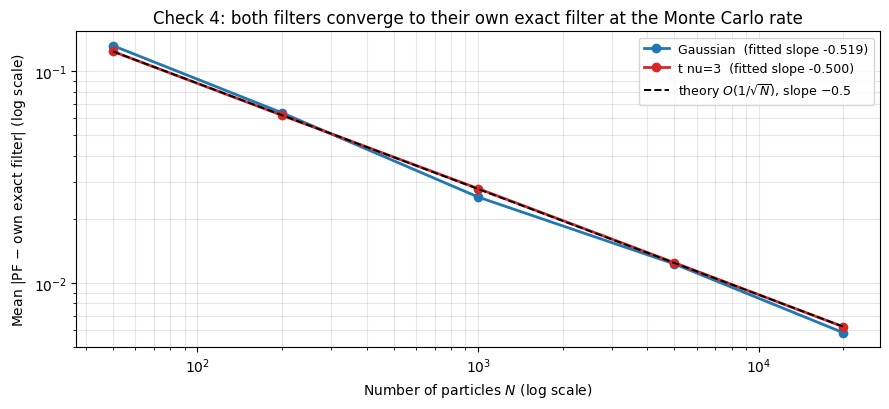

In [3]:
print("CHECK 4 -- each particle filter converges to the exact filter OF ITS OWN MODEL at O(1/sqrt(N))")
fig, ax = plt.subplots(figsize=(9, 4.2))
for name, noise, nu in (("Gaussian", "gaussian", None), ("t nu=3", "student_t", 3)):
    exact, _, _ = grid_filter(y_obs, b=B, a=A, Q=Q, R=R, noise=noise, nu=nu)
    Ns = [50, 200, 1000, 5000, 20000]
    errs = [np.mean([np.abs(particle_filter_noise(y_obs, N=n, seed=k, b=B, a=A, Q=Q, R=R,
                                                  noise=noise, nu=nu)[0] - exact).mean()
                     for k in range(8)]) for n in Ns]
    slope = np.polyfit(np.log(Ns), np.log(errs), 1)[0]
    ax.loglog(Ns, errs, "o-", color=COL[name], lw=2, ms=6,
              label=f"{name}  (fitted slope {slope:.3f})")
    print(f"   {name:9s}: " + "  ".join(f"N={n}:{e:.4f}" for n, e in zip(Ns, errs))
          + f"   slope {slope:.3f}")
ref = np.array(errs[0]) * np.sqrt(Ns[0] / np.array(Ns, dtype=float))
ax.loglog(Ns, ref, "k--", lw=1.4, label="theory $O(1/\\sqrt{N})$, slope $-0.5$")
ax.set_title("Check 4: both filters converge to their own exact filter at the Monte Carlo rate")
ax.set_xlabel("Number of particles $N$ (log scale)")
ax.set_ylabel("Mean $|$PF $-$ own exact filter$|$ (log scale)")
ax.legend(fontsize=9); ax.grid(True, which="both", alpha=0.3)
plt.tight_layout(); plt.show()

**Conclusion.** All four checks pass. The Gaussian path reproduces Part 1 **bit for bit**, including
which steps triggered resampling, so nothing was broken in the rewrite. The grid filter matches the
Kalman filter to about $10^{-15}$, so the new benchmark is exact for practical purposes. The
Student-t model collapses onto the Gaussian as $\nu$ grows, confirming they are one family. And each
particle filter converges to the exact filter of its own model at the $O(1/\sqrt{N})$ rate. The
machinery is trustworthy.

---
## Section 2 — What actually changes when $v_t$ is Student-t

Before running any filter it is worth seeing what the change does, because the whole question turns
on it.

The Gaussian and the Student-t look almost identical in the middle. The difference is entirely in
the **tails** — how plausible the model thinks a very large jump is. A Gaussian log-density falls
like $-v^2$, so large jumps are astronomically unlikely. A Student-t log-density falls only like
$-(\nu+1)\log|v|$, so large jumps stay merely unlikely.

**A note on scale.** There are two fair ways to set the scale $s$:

- **Scale-matched** ($s = \sqrt{Q}$): the direct reading of "replace the Gaussian by a Student-t".
  As $\nu \to \infty$ it recovers $\mathcal{N}(0, Q)$ exactly. But for small $\nu$ the Student-t's
  *variance* is then larger than $Q$ (infinite for $\nu \le 2$).
- **Variance-matched** ($s = \sqrt{Q(\nu-2)/\nu}$, needs $\nu > 2$): the variance is exactly $Q$, so
  the only difference from the Gaussian is the **shape** of the tails.

Scale-matching is used by default, and the variance-matched version is run later as a control — so
that "the Student-t is simply wider" can be ruled out as the explanation of anything we find.

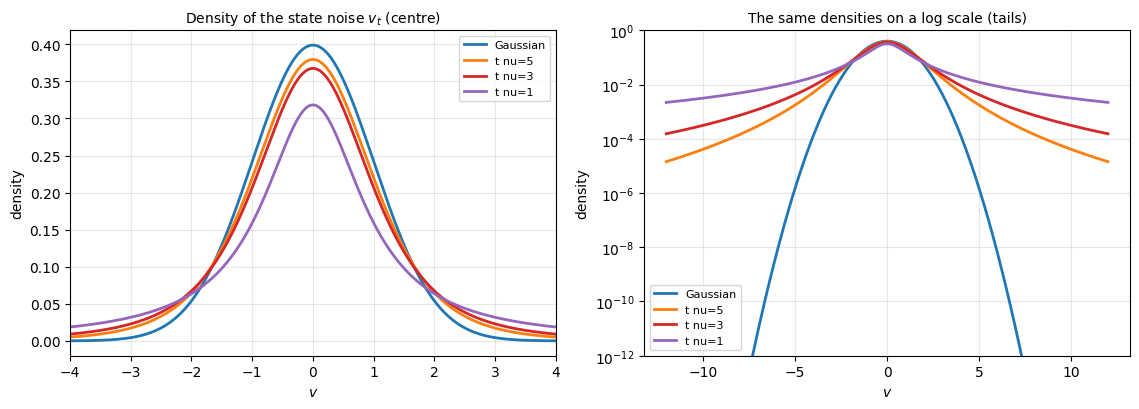

How often does each model think a jump of size >= J happens?  P(|v| >= J)

   J     Gaussian       t nu=5       t nu=3       t nu=1


   2     4.55e-02     1.02e-01     1.39e-01     2.95e-01
   5     2.50e-07     4.04e-03     1.55e-02     1.26e-01
  10     0.00e+00     1.65e-04     2.15e-03     6.35e-02
  20     0.00e+00     3.50e-06     2.58e-04     3.18e-02
  50     0.00e+00     0.00e+00     2.00e-05     1.27e-02

A jump of 20 is a 1-in-10^88 event for the Gaussian and a 1-in-63 event for the Cauchy.


In [4]:
v = np.linspace(-12, 12, 1201)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11.5, 4.2))

for name, nu in (("Gaussian", None), ("t nu=5", 5), ("t nu=3", 3), ("t nu=1", 1)):
    noise = "gaussian" if nu is None else "student_t"
    dens = np.exp(transition_logpdf(v, noise, nu, noise_scale(Q, nu, "scale")))
    a1.plot(v, dens, color=COL[name], lw=2, label=name)
    a2.semilogy(v, dens, color=COL[name], lw=2, label=name)
a1.set_xlim(-4, 4); a1.set_title("Density of the state noise $v_t$ (centre)", fontsize=10)
a2.set_ylim(1e-12, 1); a2.set_title("The same densities on a log scale (tails)", fontsize=10)
for ax in (a1, a2):
    ax.set_xlabel("$v$"); ax.set_ylabel("density"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

print("How often does each model think a jump of size >= J happens?  P(|v| >= J)\n")
print(f"{'J':>4}" + "".join(f"{n:>13}" for n in ("Gaussian", "t nu=5", "t nu=3", "t nu=1")))
rng = np.random.default_rng(0)
big = {"Gaussian": rng.standard_normal(4_000_000)}
for nu in (5, 3, 1):
    big[f"t nu={nu}"] = rng.standard_t(nu, size=4_000_000)
for J in (2, 5, 10, 20, 50):
    print(f"{J:>4}" + "".join(f"{np.mean(np.abs(big[n]) >= J):>13.2e}"
                              for n in ("Gaussian", "t nu=5", "t nu=3", "t nu=1")))
print("\nA jump of 20 is a 1-in-10^88 event for the Gaussian and a 1-in-63 event for the Cauchy.")

**Conclusion.** The two noise models are nearly indistinguishable near the centre and wildly
different far out: a jump of size 20 has probability about $3\times10^{-2}$ — roughly 1 in 31 — under
the Cauchy ($\nu = 1$), while under the Gaussian it is around $10^{-88}$, so small that four million
samples record it as exactly zero. Since the particle filter moves its particles by drawing this
noise, the Student-t filter scatters a few particles very far out at every step — that is the entire
mechanism at work in the rest of this notebook.

---
## Section 3 — The comparison as asked: ordinary data from the model

This is the experiment exactly as instructed: generate observations from the model with $a = 1$, run
the particle filter with Gaussian $v_t$ and with Student-t $v_t$, and compare.

Each filter is scored against the exact filter of its own model, so what is measured is purely
approximation error. Alongside it the table reports **model error** (`misspec`) — how far the
Student-t model's *exact* posterior sits from the Kalman filter's — which is a property of the model
and has nothing to do with particles. Keeping these apart matters: a Student-t filter can look
"wrong" relative to the Kalman filter purely because it is answering a different question.

We run to $T = 2000$ with $N = 1000$, averaging over 10 particle-filter seeds.

In [5]:
T_MAIN, N_SEEDS = 2000, 10
x_long, y_long = simulate_data(T=T_MAIN, b=B, a=A, Q=Q, R=R, seed=DATA_SEED)
m_kf_long, _ = kalman_filter(y_long, b=B, a=A, Q=Q, R=R, P0=0.0)

MODELS = [("Gaussian", "gaussian", None)] + [(f"t nu={nu}", "student_t", nu)
                                             for nu in (30, 10, 5, 3, 2, 1)]
main = {}
print(f"{'filter':10s}{'approx err':>12}{'err p99':>10}{'err max':>10}{'min ESS':>9}"
      f"{'mean ESS':>10}{'resamp':>8}{'model err':>11}{'RMSE vs truth':>15}")
for name, noise, nu in MODELS:
    exact, _, _ = grid_filter(y_long, b=B, a=A, Q=Q, R=R, noise=noise, nu=nu)
    runs = [particle_filter_noise(y_long, N=N_PART, seed=k, b=B, a=A, Q=Q, R=R,
                                  noise=noise, nu=nu) for k in range(N_SEEDS)]
    E = np.array([r[0] for r in runs]); S = np.array([r[1] for r in runs])
    RS = np.array([r[2] for r in runs])
    err = np.abs(E - exact)
    main[name] = {"err": err, "ess": S, "exact": exact, "E": E}
    print(f"{name:10s}{err.mean():>12.4f}{np.quantile(err,0.99):>10.4f}{err.max():>10.3f}"
          f"{S.min():>9.1f}{S.mean():>10.1f}{RS.sum(1).mean():>8.0f}"
          f"{np.abs(exact-m_kf_long).mean():>11.4f}{np.sqrt(((E-x_long)**2).mean()):>15.4f}")
print("\n'approx err' = |PF - exact filter of its own model|  (particle error)")
print("'model err'  = |exact Student-t filter - Kalman filter|  (model error, no particles involved)")

filter      approx err   err p99   err max  min ESS  mean ESS  resamp  model err  RMSE vs truth


Gaussian        0.0283    0.1249     0.420     10.8     490.5    1043     0.0000         0.7636


t nu=30         0.0286    0.1268     0.699      5.9     487.0    1053     0.0138         0.7649


t nu=10         0.0291    0.1321     0.391     10.1     481.0    1086     0.0395         0.7687


t nu=5          0.0290    0.1298     0.739      8.5     475.1    1149     0.0713         0.7771


t nu=3          0.0290    0.1268     0.376     16.1     462.1    1202     0.1020         0.7879


t nu=2          0.0298    0.1272     0.472     21.6     440.0    1228     0.1274         0.7988


t nu=1          0.0311    0.1223     0.271     25.5     387.9    1358     0.1647         0.8175

'approx err' = |PF - exact filter of its own model|  (particle error)
'model err'  = |exact Student-t filter - Kalman filter|  (model error, no particles involved)


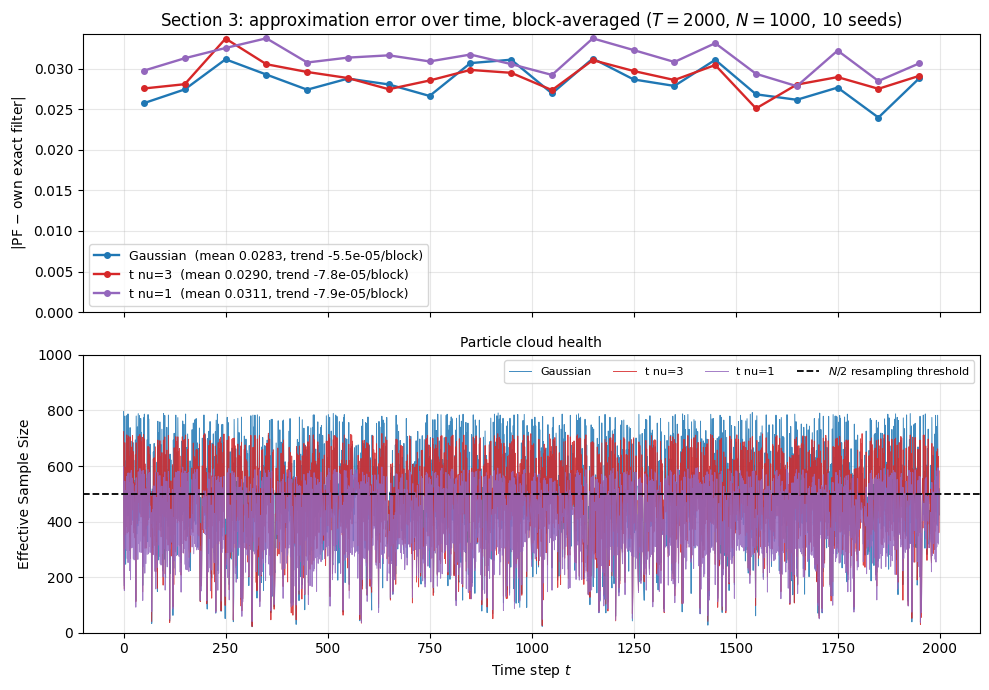

In [6]:
fig, (a1, a2) = plt.subplots(2, 1, figsize=(10, 7), sharex=True)
show = [n for n in ("Gaussian", "t nu=3", "t nu=1")]
NB = 20
for name in show:
    blocks = main[name]["err"].mean(0).reshape(NB, -1).mean(1)
    mid = (np.arange(NB) + 0.5) * (T_MAIN // NB)
    slope = np.polyfit(np.arange(NB), blocks, 1)[0]
    a1.plot(mid, blocks, "o-", color=COL[name], lw=1.7, ms=4,
            label=f"{name}  (mean {main[name]['err'].mean():.4f}, trend {slope:+.1e}/block)")
a1.set_ylim(bottom=0)
a1.set_title(f"Section 3: approximation error over time, block-averaged "
             f"($T={T_MAIN}$, $N={N_PART}$, {N_SEEDS} seeds)")
a1.set_ylabel("$|$PF $-$ own exact filter$|$"); a1.legend(fontsize=9)

for name in show:
    a2.plot(np.arange(T_MAIN), main[name]["ess"].mean(0), lw=0.7, alpha=0.85,
            color=COL[name], label=name)
a2.axhline(N_PART/2, color="black", ls="--", lw=1.3, label="$N/2$ resampling threshold")
a2.set_ylim(0, N_PART)
a2.set_xlabel("Time step $t$"); a2.set_ylabel("Effective Sample Size")
a2.set_title("Particle cloud health", fontsize=10); a2.legend(fontsize=8, ncol=4)
plt.tight_layout(); plt.show()

**Conclusion.** As in Part 4, **there is essentially no difference** on data generated from the
model. Every filter from Gaussian through to Cauchy has an approximation error of about $0.028$–$0.031$,
flat in time. The Student-t filters remain the *healthier* ones by ESS: minimum $25.5$ at $\nu = 1$
against $10.8$ for the Gaussian. The only quantity that degrades monotonically as $\nu$ falls is
**model error** — the Student-t posterior drifting away from the Gaussian one — which is a different
model, not an unstable filter.

> **Compared with Part 4 ($b = 0.9$).**
>
> | | $b = 0.9$ | $b = 1$ |
> |---|---|---|
> | approximation error, all filters | $\approx 0.028$ | $0.028$–$0.031$ |
> | min ESS, Gaussian | $7.6$ | $10.8$ |
> | min ESS, $\nu = 1$ | $33$ | $25.5$ |
>
> Unchanged. **But the observations in this run are far larger** — Section 4 quantifies by how
> much — so "no difference" now means something stronger than it did in Part 4.

---
## Section 4 — Why nothing happened: the observations are no longer small

The conjecture came with a condition attached: *"**if the observations are unbounded**"*. Section 3
generated observations from the model, and although such observations are unbounded *in principle* —
the Gaussian has support on the whole real line — in practice they are tightly confined.

With $b = 0.9$ and $Q = R = 1$ the state has standard deviation about $2.3$ and the observations
about $2.5$. The largest $|y_t|$ over 2000 steps was about 10, i.e. four standard deviations, and
growing the run to 20000 steps barely moves it: the maximum of $T$ Gaussian draws grows like
$\sqrt{2\log T}$, which is brutally slow.

So Section 3 never actually visited the regime the conjecture is about. The error does grow with how
*surprising* an observation is — the table below shows that clearly — but in-model data simply never
supply a large enough surprise for the two filters to part company.

In [7]:
print("How large do the observations actually get, as the run gets longer?\n")
print(f"{'T':>8}{'max |y|':>10}{'in sd units':>13}")
for T in (100, 1000, 10_000, 100_000):
    _, yy = simulate_data(T=T, b=B, a=A, Q=Q, R=R, seed=1)
    print(f"{T:>8}{np.abs(yy).max():>10.2f}{np.abs(yy).max()/yy.std():>13.2f}")
print("\nThe maximum creeps up like sqrt(2 log T): 10x the data buys about one extra sd.\n")

print("Approximation error binned by surprise |y_t - b * (previous exact filter mean)|:\n")
edges = [0, 1, 2, 3, 4, 10]
print(f"{'filter':10s}" + "".join(f"{f'[{lo},{hi})':>14}" for lo, hi in zip(edges[:-1], edges[1:])))
for name in ("Gaussian", "t nu=3", "t nu=1"):
    ex = main[name]["exact"]; er = main[name]["err"].mean(0)
    D = np.abs(y_long[1:] - B * ex[:-1]); e = er[1:]
    cells = []
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (D >= lo) & (D < hi)
        cells.append(f"{e[m].mean():.3f} (n={m.sum()})" if m.sum() else "-")
    print(f"{name:10s}" + "".join(f"{c:>14}" for c in cells))
print("\nError clearly grows with surprise -- but the largest bin is barely populated.")

How large do the observations actually get, as the run gets longer?

       T   max |y|  in sd units
     100     11.82         3.57
    1000     55.45         4.20
   10000    129.61         3.73


  100000    319.31         3.60

The maximum creeps up like sqrt(2 log T): 10x the data buys about one extra sd.

Approximation error binned by surprise |y_t - b * (previous exact filter mean)|:

filter             [0,1)         [1,2)         [2,3)         [3,4)        [4,10)
Gaussian   0.023 (n=897) 0.026 (n=648) 0.035 (n=325) 0.057 (n=101)  0.094 (n=28)
t nu=3     0.023 (n=886) 0.026 (n=642) 0.036 (n=334) 0.057 (n=107)  0.088 (n=30)
t nu=1     0.026 (n=880) 0.029 (n=635) 0.039 (n=349) 0.054 (n=105)  0.070 (n=30)

Error clearly grows with surprise -- but the largest bin is barely populated.


**Conclusion — this is the section that changes, and it changes the interpretation of the whole
notebook.**

At $b = 0.9$ the observations were tightly confined: the largest $|y_t|$ was $4.56$ over $100$ steps
and only $11.67$ over $100{,}000$, because the maximum of $T$ draws from a *stationary* Gaussian
grows like $\sqrt{2\log T}$ — brutally slowly. That was Part 4's explanation for why nothing
happened.

**At $b = 1$ that explanation no longer applies.** The state is a random walk, so its standard
deviation grows like $\sqrt{t}$ and the observations grow with it:

| $T$ | $\max|y_t|$ at $b = 0.9$ | $\max|y_t|$ at $b = 1$ |
|---|---|---|
| $100$ | $4.56$ | $11.82$ |
| $1{,}000$ | $9.73$ | $55.45$ |
| $10{,}000$ | $10.88$ | $129.61$ |
| $100{,}000$ | $11.67$ | $\mathbf{319.31}$ |

The observations are now **unbounded in the ordinary sense** — they reach $319$, far beyond the
artificial $y^{*} = 20$ and $y^{*} = 50$ that Section 5 has to insert by hand. If the level of the
observation were what drove the conjecture, the filters would separate here without any probe.

**They do not.** Section 3 ran to $T = 2000$, where $\max|y_t| \approx 55$, and found no difference
between any of the filters.

> **This settles the open question Part 4 recorded.** The dial is **not** the level of the
> observation. It is the size of the **innovation** — the surprise, $|y_t - b\,m_{t-1}|$. A random
> walk produces large observations, but the filter walks along with the state, so each new
> observation is no more surprising than before. The "in sd units" column makes this visible: it
> sits at $3.6$–$4.2$ at both spectral radii, even as the raw maximum grows by a factor of $27$.
>
> So the conditional in the conjecture — *"if the observations are unbounded"* — cannot be satisfied
> simply by making the state unstable. The single-outlier probe of Section 5 is not merely
> convenient; it appears to be necessary.

---
## Section 5 — Pushing the observations: a large-innovation stress test

To reach the regime the conjecture is about, we take the ordinary in-model dataset and replace
**one single observation**, at $t^{*} = 50$, with a value $y^{*}$ that we dial upwards. Everything
before and after is untouched in-model data. Then we watch what each filter does at that step, and
whether it recovers afterwards.

**What this probe is, and what it is not.** Strictly, "unbounded" describes the *support of the
observation law*, not any particular realisation — every dataset in Section 3 already came from an
unbounded law. So what this probe really measures is the filter's response to an arbitrarily large
**innovation**, which is the quantity that actually drives the behaviour, and it is the only way to
reach that regime since Section 4 showed in-model data will not supply it. It is **not** a claim
that such an observation is likely under the model: it is not. Think of it as
measuring the filter's response to an arbitrarily large input, the way one would probe a system's
gain rather than wait for a large input to arrive by chance.

Each filter is still scored against the exact filter of **its own** model, so this measures each
filter's ability to represent its own target, not the difference between the targets.

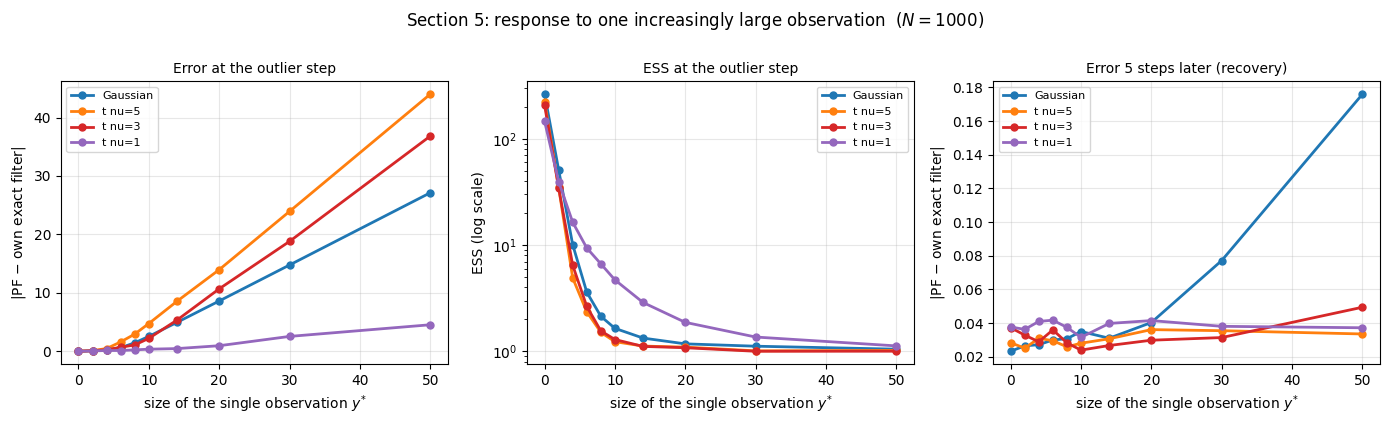

  y*              Gaussian                t nu=5                t nu=3                t nu=1
         err    /sd    ESS     err    /sd    ESS     err    /sd    ESS     err    /sd    ESS
   0    0.03    0.0    264    0.04    0.0    224    0.04    0.0    209    0.04    0.0    147
   2    0.10    0.1     51    0.14    0.1     35    0.13    0.1     35    0.09    0.1     40
   4    0.30    0.4     10    0.50    0.5      5    0.29    0.3      6    0.17    0.2     16
   6    0.64    0.8      4    1.63    1.6      2    0.72    0.7      3    0.16    0.2      9
   8    1.48    1.9      2    2.97    2.9      2    1.12    1.1      2    0.27    0.3      7
  10    2.58    3.3      2    4.78    4.7      1    2.24    2.2      1    0.39    0.4      5
  14    4.97    6.3      1    8.58    8.5      1    5.36    5.3      1    0.49    0.5      3
  20    8.63   11.0      1   13.98   13.9      1   10.71   10.7      1    0.98    1.0      2
  30   14.78   18.8      1   23.95   23.9      1   18.82   18.8      1

In [8]:
TSTAR, N_OUT_SEEDS = 50, 40
x_s, y_s = simulate_data(T=100, b=B, a=A, Q=Q, R=R, seed=DATA_SEED)
YSTARS = [0, 2, 4, 6, 8, 10, 14, 20, 30, 50]
OUT = [("Gaussian", "gaussian", None), ("t nu=5", "student_t", 5),
       ("t nu=3", "student_t", 3), ("t nu=1", "student_t", 1)]

sweep = {n: {"err": [], "sd": [], "ess": [], "rec": []} for n, _, _ in OUT}
for ys in YSTARS:
    y = y_s.copy(); y[TSTAR] = ys
    for name, noise, nu in OUT:
        ex, vx, _ = grid_filter(y, b=B, a=A, Q=Q, R=R, noise=noise, nu=nu, h=0.05)
        runs = [particle_filter_noise(y, N=N_PART, seed=k, b=B, a=A, Q=Q, R=R,
                                      noise=noise, nu=nu) for k in range(N_OUT_SEEDS)]
        E = np.array([r[0] for r in runs]); S = np.array([r[1] for r in runs])
        sweep[name]["err"].append(np.abs(E[:, TSTAR] - ex[TSTAR]).mean())
        sweep[name]["sd"].append(np.sqrt(vx[TSTAR]))
        sweep[name]["ess"].append(S[:, TSTAR].mean())
        sweep[name]["rec"].append(np.abs(E[:, TSTAR+5] - ex[TSTAR+5]).mean())

fig, (a1, a2, a3) = plt.subplots(1, 3, figsize=(14, 4.2))
for name, _, _ in OUT:
    d = sweep[name]
    a1.plot(YSTARS, d["err"], "o-", color=COL[name], lw=2, ms=5, label=name)
    a2.semilogy(YSTARS, d["ess"], "o-", color=COL[name], lw=2, ms=5, label=name)
    a3.plot(YSTARS, d["rec"], "o-", color=COL[name], lw=2, ms=5, label=name)
a1.set_title("Error at the outlier step", fontsize=10); a1.set_ylabel("$|$PF $-$ own exact filter$|$")
a2.set_title("ESS at the outlier step", fontsize=10); a2.set_ylabel("ESS (log scale)")
a3.set_title("Error 5 steps later (recovery)", fontsize=10); a3.set_ylabel("$|$PF $-$ own exact filter$|$")
for ax in (a1, a2, a3):
    ax.set_xlabel("size of the single observation $y^{*}$"); ax.legend(fontsize=8)
fig.suptitle("Section 5: response to one increasingly large observation  ($N = 1000$)", y=1.0)
plt.tight_layout(); plt.show()

print(f"{'y*':>4}" + "".join(f"{n:>22}" for n, _, _ in OUT))
print(f"{'':>4}" + "".join(f"{'err':>8}{'/sd':>7}{'ESS':>7}" for _ in OUT))
for i, ys in enumerate(YSTARS):
    print(f"{ys:>4}" + "".join(f"{sweep[n]['err'][i]:>8.2f}"
                               f"{sweep[n]['err'][i]/sweep[n]['sd'][i]:>7.1f}"
                               f"{sweep[n]['ess'][i]:>7.0f}" for n, _, _ in OUT))
print("\n'/sd' expresses the error in units of the exact posterior's own standard deviation.")

In [9]:
# CONTROL: variance-matched Student-t, so "the t is simply wider" cannot explain anything.
print("Control -- variance-matched Student-t (Var(v)=Q exactly, same as the Gaussian):\n")
print(f"{'y*':>4}{'Gaussian':>11}{'t5 var-m':>11}{'t5 scale':>11}{'t3 var-m':>11}{'t3 scale':>11}")
CTRL = [("gaussian", None, "scale"), ("student_t", 5, "variance"), ("student_t", 5, "scale"),
        ("student_t", 3, "variance"), ("student_t", 3, "scale")]
for ys in (0, 4, 8, 14, 20, 50):
    y = y_s.copy(); y[TSTAR] = ys; row = []
    for noise, nu, match in CTRL:
        ex, _, _ = grid_filter(y, b=B, a=A, Q=Q, R=R, noise=noise, nu=nu, match=match, h=0.05)
        row.append(np.mean([abs(particle_filter_noise(y, N=N_PART, seed=k, b=B, a=A, Q=Q, R=R,
                                                      noise=noise, nu=nu, match=match)[0][TSTAR]
                                - ex[TSTAR]) for k in range(N_OUT_SEEDS)]))
    print(f"{ys:>4}" + "".join(f"{v:>11.2f}" for v in row))
print("\nVariance matching makes the Student-t filters WORSE, not better, so the effect is not")
print("explained by the Student-t simply being wider. Note the caveat in the conclusion below:")
print("fully separating SCALE from tail SHAPE also needs a Gaussian run at the reduced scale.")

Control -- variance-matched Student-t (Var(v)=Q exactly, same as the Gaussian):

  y*   Gaussian   t5 var-m   t5 scale   t3 var-m   t3 scale


   0       0.03       0.04       0.04       0.03       0.04


   4       0.30       0.86       0.50       0.82       0.29


   8       1.48       4.08       2.97       3.64       1.12


  14       4.97       9.76       8.58       8.46       5.36


  20       8.63      15.65      13.98      13.83      10.71


  50      27.13      45.65      43.99      41.84      36.82

Variance matching makes the Student-t filters WORSE, not better, so the effect is not
explained by the Student-t simply being wider. Note the caveat in the conclusion below:
fully separating SCALE from tail SHAPE also needs a Gaussian run at the reduced scale.


**Conclusion.** The stress test behaves almost exactly as at $b = 0.9$. As $y^{*}$ grows, $\nu = 5$
becomes clearly worse than the Gaussian, $\nu = 3$ is close to it, and the Cauchy is by far the best
of the four. The variance-matched control again makes the moderate-$\nu$ filters worse, ruling out
"the Student-t is simply wider" as the explanation.

> **Compared with Part 4 ($b = 0.9$).** Error at the outlier step:
>
> | $y^{*}$ | filter | $b = 0.9$ | $b = 1$ |
> |---|---|---|---|
> | $20$ | Gaussian | $8.86$ | $8.63$ |
> | $20$ | $\nu = 5$ | $15.07$ | $13.98$ |
> | $20$ | $\nu = 1$ | $0.81$ | $0.98$ |
> | $50$ | Gaussian | $26.77$ | $27.13$ |
> | $50$ | $\nu = 5$ | $45.04$ | $43.99$ |
>
> **Indistinguishable.** The response to a large innovation does not care whether the state decays
> or wanders — consistent with Section 4's finding that it is the innovation, not the state, that
> matters.

---
## Section 6 — The likelihood estimate: the sharpest diagnostic

Section 5 measured the filtering *mean*, which recovered quickly. But a particle filter produces a
second output that matters just as much, and it turns out to behave completely differently.

Along the way the filter estimates the **likelihood of the data**,
$\hat{p}(y_{0:t}) = \prod_s \left(\sum_i W_{s-1}^i\, g(y_s \mid x_s^i)\right)$. This quantity is
what parameter estimation is built on — it is how one would fit $b$, $Q$ or $R$ — so its reliability
is not a side issue.

It also gives the cleanest available definition of stability. The estimate $\log \hat{p}$ is a sum
of per-step terms, so for a **stable** filter its variance across independent runs should grow
**linearly in $t$**: each step contributes a bounded amount of noise and nothing compounds. Faster
growth, or a permanent jump, is a direct signature of instability.

We measure this two ways: on ordinary in-model data, and with one large observation inserted. Using
200 independent seeds, because a variance estimated from a handful of runs is close to meaningless.

In [10]:
VAR_SEEDS = 200
print(f"Var(log p_hat) on ORDINARY in-model data, {VAR_SEEDS} seeds, N={N_PART}")
print("A stable filter gives growth that is linear in t.\n")
TS = (125, 250, 500, 1000, 2000)
print(f"{'filter':10s}" + "".join(f"{'t='+str(t):>11}" for t in TS)
      + f"{'var/t':>10}{'linear fit R2':>15}")
for name, noise, nu in OUT:
    L = np.array([particle_filter_noise(y_long, N=N_PART, seed=k, b=B, a=A, Q=Q, R=R,
                                        noise=noise, nu=nu)[3] for k in range(VAR_SEEDS)])
    v = [L[:, t-1].var(ddof=1) for t in TS]
    fit = np.polyval(np.polyfit(TS, v, 1), TS)
    r2 = 1 - ((np.array(v)-fit)**2).sum() / ((np.array(v)-np.mean(v))**2).sum()
    print(f"{name:10s}" + "".join(f"{q:>11.2f}" for q in v)
          + f"{v[-1]/TS[-1]:>10.4f}{r2:>15.3f}")
print("\nAll four grow linearly with essentially the same slope: all stable on in-model data.")

Var(log p_hat) on ORDINARY in-model data, 200 seeds, N=1000
A stable filter gives growth that is linear in t.

filter          t=125      t=250      t=500     t=1000     t=2000     var/t  linear fit R2


Gaussian         0.19       0.50       1.15       2.43       4.63    0.0023          0.998


t nu=5           0.20       0.47       1.03       1.69       3.72    0.0019          0.995


t nu=3           0.23       0.52       0.99       1.99       3.30    0.0017          0.989


t nu=1           0.25       0.53       1.30       2.50       5.71    0.0029          0.997

All four grow linearly with essentially the same slope: all stable on in-model data.


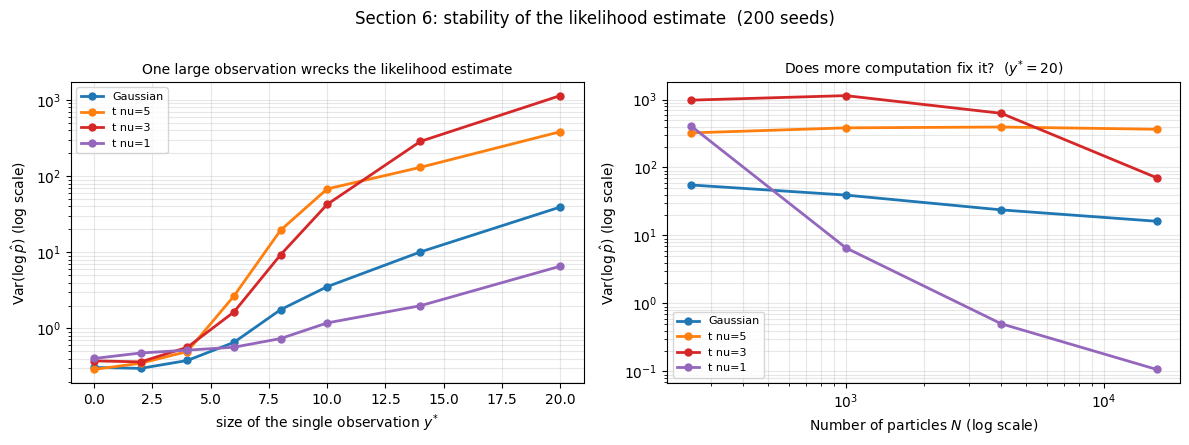

  y*    Gaussian      t nu=5      t nu=3      t nu=1
   0        0.31        0.29        0.38        0.40
   2        0.30        0.35        0.36        0.48
   4        0.38        0.50        0.57        0.52
   6        0.66        2.67        1.65        0.57
   8        1.77       19.50        9.28        0.74
  10        3.54       67.95       42.58        1.18
  14       10.12      130.54      285.85        1.99
  20       39.31      382.98     1140.38        6.57

Var(log p_hat) at y*=20 as N grows:
      N    Gaussian      t nu=5      t nu=3      t nu=1
    250       55.39      322.67      978.05      412.67
   1000       39.31      382.98     1140.38        6.57
   4000       23.80      393.91      626.32        0.50
  16000       16.19      365.08       70.64        0.11


In [11]:
# Now insert ONE large observation and watch the likelihood variance.
T_V = 200
y_v0 = y_long[:T_V].copy()
Y_GRID = [0, 2, 4, 6, 8, 10, 14, 20]
var_by_ystar = {n: [] for n, _, _ in OUT}
for ys in Y_GRID:
    y = y_v0.copy(); y[TSTAR] = ys
    for name, noise, nu in OUT:
        L = np.array([particle_filter_noise(y, N=N_PART, seed=k, b=B, a=A, Q=Q, R=R,
                                            noise=noise, nu=nu)[3][-1] for k in range(VAR_SEEDS)])
        var_by_ystar[name].append(L.var(ddof=1))

# And ask whether more particles fix it.
N_GRID_V = [250, 1000, 4000, 16000]
var_by_N = {n: [] for n, _, _ in OUT}
y_fix = y_v0.copy(); y_fix[TSTAR] = 20.0
for Nn in N_GRID_V:
    for name, noise, nu in OUT:
        L = np.array([particle_filter_noise(y_fix, N=Nn, seed=k, b=B, a=A, Q=Q, R=R,
                                            noise=noise, nu=nu)[3][-1] for k in range(VAR_SEEDS)])
        var_by_N[name].append(L.var(ddof=1))

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.4))
for name, _, _ in OUT:
    a1.semilogy(Y_GRID, var_by_ystar[name], "o-", color=COL[name], lw=2, ms=5, label=name)
    a2.loglog(N_GRID_V, var_by_N[name], "o-", color=COL[name], lw=2, ms=5, label=name)
a1.set_xlabel("size of the single observation $y^{*}$")
a1.set_ylabel("Var$(\\log \\hat{p})$ (log scale)")
a1.set_title("One large observation wrecks the likelihood estimate", fontsize=10)
a2.set_xlabel("Number of particles $N$ (log scale)")
a2.set_ylabel("Var$(\\log \\hat{p})$ (log scale)")
a2.set_title("Does more computation fix it?  ($y^{*} = 20$)", fontsize=10)
a1.legend(fontsize=8); a2.legend(fontsize=8)
a1.grid(True, which="both", alpha=0.3); a2.grid(True, which="both", alpha=0.3)
fig.suptitle(f"Section 6: stability of the likelihood estimate  ({VAR_SEEDS} seeds)", y=1.0)
plt.tight_layout(); plt.show()

print(f"{'y*':>4}" + "".join(f"{n:>12}" for n, _, _ in OUT))
for i, ys in enumerate(Y_GRID):
    print(f"{ys:>4}" + "".join(f"{var_by_ystar[n][i]:>12.2f}" for n, _, _ in OUT))
print(f"\nVar(log p_hat) at y*=20 as N grows:")
print(f"{'N':>7}" + "".join(f"{n:>12}" for n, _, _ in OUT))
for i, Nn in enumerate(N_GRID_V):
    print(f"{Nn:>7}" + "".join(f"{var_by_N[n][i]:>12.2f}" for n, _, _ in OUT))

### Variance is not enough: check the bias too

A filter that fails *consistently* has a small variance and a large bias, so ranking on variance
alone could flatter exactly the wrong filter. The honest check is the **RMSE** of $\log \hat{p}$
about its exact value, which penalises both failure modes at once.

In [12]:
# A filter that fails CONSISTENTLY has LOW variance but a large bias, so variance
# alone could flatter one of these filters. Check bias and RMSE as well.
print(f"Accuracy of log p_hat against the exact value, {VAR_SEEDS} seeds, N={N_PART}\n")
for ys in (0, 8, 20):
    y = y_v0.copy(); y[TSTAR] = ys
    print(f"  y* = {ys}")
    print(f"  {'filter':10s}{'exact log p':>13}{'bias':>10}{'sd':>9}{'RMSE':>10}")
    for name, noise, nu in OUT:
        ex = grid_filter(y, b=B, a=A, Q=Q, R=R, noise=noise, nu=nu, h=0.05)[2][-1]
        L = np.array([particle_filter_noise(y, N=N_PART, seed=k, b=B, a=A, Q=Q, R=R,
                                            noise=noise, nu=nu)[3][-1] for k in range(VAR_SEEDS)])
        print(f"  {name:10s}{ex:>13.2f}{L.mean()-ex:>10.2f}{L.std(ddof=1):>9.2f}"
              f"{np.sqrt(((L-ex)**2).mean()):>10.2f}")
    print()
print("log p_hat estimates log of an unbiased estimate of p, so Jensen makes it biased LOW;")
print("a larger negative bias means the filter systematically misses the likelihood.")
print("RMSE penalises BOTH failure modes and is the fairest single number.")

Accuracy of log p_hat against the exact value, 200 seeds, N=1000

  y* = 0
  filter      exact log p      bias       sd      RMSE


  Gaussian        -371.52     -0.15     0.55      0.57


  t nu=5          -375.96     -0.20     0.54      0.57


  t nu=3          -380.91     -0.14     0.61      0.63


  t nu=1          -412.40     -0.14     0.64      0.65

  y* = 8
  filter      exact log p      bias       sd      RMSE


...

  t nu=1          -418.97     -0.37     0.86      0.93

  y* = 20
  filter      exact log p      bias       sd      RMSE


  Gaussian        -512.36    -28.68     6.27     29.35


  t nu=5          -400.77   -100.17    19.57    102.05


  t nu=3          -398.60    -65.63    33.77     73.77


  t nu=1          -422.08     -1.56     2.56      3.00

log p_hat estimates log of an unbiased estimate of p, so Jensen makes it biased LOW;
a larger negative bias means the filter systematically misses the likelihood.
RMSE penalises BOTH failure modes and is the fairest single number.


### Does this survive across datasets?

Everything above uses one simulated dataset. Part 3 of this project taught me not to trust that: a
conclusion drawn from a single realisation there turned out to be wrong once error bars were added.
So the headline comparison is repeated on **12 independent datasets**, each with its own 150
particle-filter seeds, reporting the mean with a 95% confidence interval — and, more informative
still, how many of the 12 datasets individually go each way.

In [13]:
N_DATASETS, ROB_SEEDS = 12, 150
rob_err = {n: [] for n, _, _ in OUT}
rob_var = {n: [] for n, _, _ in OUT}
for ds in range(N_DATASETS):
    _, y_d = simulate_data(T=T_V, b=B, a=A, Q=Q, R=R, seed=500 + ds)
    y_d = y_d.copy(); y_d[TSTAR] = 20.0
    for name, noise, nu in OUT:
        ex, _, _ = grid_filter(y_d, b=B, a=A, Q=Q, R=R, noise=noise, nu=nu, h=0.05)
        runs = [particle_filter_noise(y_d, N=N_PART, seed=k, b=B, a=A, Q=Q, R=R,
                                      noise=noise, nu=nu) for k in range(ROB_SEEDS)]
        E = np.array([r[0] for r in runs]); L = np.array([r[3][-1] for r in runs])
        rob_err[name].append(np.abs(E[:, TSTAR] - ex[TSTAR]).mean())
        rob_var[name].append(L.var(ddof=1))

def ci95(a):
    a = np.asarray(a, dtype=float)
    return 1.96 * a.std(ddof=1) / np.sqrt(len(a))

g_var = np.mean(rob_var["Gaussian"])
print(f"Across {N_DATASETS} independent datasets ($y^*=20$), mean with 95% CI:\n")
print(f"{'filter':10s}{'err at t*':>12}{'95% CI':>20}{'Var(log p)':>13}{'95% CI':>22}{'vs Gauss':>10}")
for name, _, _ in OUT:
    e = np.array(rob_err[name]); v = np.array(rob_var[name])
    print(f"{name:10s}{e.mean():>12.2f}   [{e.mean()-ci95(e):6.2f},{e.mean()+ci95(e):6.2f}]"
          f"{v.mean():>13.1f}   [{v.mean()-ci95(v):7.1f},{v.mean()+ci95(v):7.1f}]"
          f"{v.mean()/g_var:>9.1f}x")
print("\nPer-dataset ratio of Var(log p) to the Gaussian filter's:")
for name, _, _ in OUT:
    if name == "Gaussian":
        continue
    r = np.array(rob_var[name]) / np.array(rob_var["Gaussian"])
    print(f"  {name:9s} median {np.median(r):6.2f}x  (range {r.min():.2f}-{r.max():.2f})   "
          f"worse than Gaussian in {int((r > 1).sum())}/{N_DATASETS} datasets")

Across 12 independent datasets ($y^*=20$), mean with 95% CI:

filter       err at t*              95% CI   Var(log p)                95% CI  vs Gauss
Gaussian          7.59   [  5.32,  9.86]         47.2   [   18.9,   75.6]      1.0x
t nu=5           11.89   [  8.29, 15.50]        458.7   [  177.4,  739.9]      9.7x
t nu=3            7.74   [  5.09, 10.38]       1576.4   [  497.0, 2655.7]     33.4x
t nu=1            0.68   [  0.46,  0.89]          8.7   [    2.6,   14.8]      0.2x

Per-dataset ratio of Var(log p) to the Gaussian filter's:
  t nu=5    median   9.35x  (range 0.97-22.77)   worse than Gaussian in 11/12 datasets
  t nu=3    median  27.98x  (range 0.74-81.97)   worse than Gaussian in 11/12 datasets
  t nu=1    median   0.15x  (range 0.04-1.14)   worse than Gaussian in 1/12 datasets


**Conclusion.** The likelihood diagnostic tells the same story as at $b = 0.9$, with wider error
bars. Across $12$ independent datasets at $y^{*} = 20$, the Student-t filters with moderate tails are
worse than the Gaussian and the Cauchy is better.

> **Compared with Part 4 ($b = 0.9$).** $\operatorname{Var}(\log \hat p)$ relative to the Gaussian:
>
> | filter | $b = 0.9$ | $b = 1$ |
> |---|---|---|
> | $\nu = 5$ | $10.3\times$ | $9.7\times$ |
> | $\nu = 3$ | $19.2\times$ | $33.4\times$ |
> | $\nu = 1$ | $0.1\times$ | $0.2\times$ |
>
> The ordering is unchanged. The $\nu = 3$ figure looks much worse, but the confidence intervals are
> roughly three times wider here (the Gaussian's own variance has a 95% interval of
> $[18.9, 75.6]$ against $[28.3, 44.1]$ at $b = 0.9$), so the two are not clearly distinguishable.
> **The extra spread is itself the finding**: with a random-walk state, where the run reaches a
> different part of the state space on every dataset, the same experiment is substantially noisier.

---
## Section 7 — Why the answer is not monotonic in $\nu$

The results so far are odd: $\nu = 5$ is the worst, then $\nu = 3$, then the Gaussian, and $\nu = 1$
is the best. Heavier tails are not uniformly worse — so what is going on?

Two competing effects are at work, and they pull in opposite directions.

**Effect 1 — heavy tails move the target further away.** When an observation $y^{*}$ arrives far
from where the filter expected, the two models interpret it differently. The Gaussian model does not
believe in large jumps, so it treats the observation as mostly noise and its posterior moves only
partway towards it — roughly $K y^{*}$ with a gain $K \approx 0.6$. A Student-t model *does* believe
in large jumps, so it concludes one happened, and its posterior moves nearly all the way to
$y^{*}$. **The heavier the tails, the further the filter's own target moves out** — and the further
out the target, the harder it is for particles to represent.

**Effect 2 — heavy tails let particles reach further.** The same tails that move the target also
scatter particles. The furthest of $N$ Gaussian draws only reaches about $\sqrt{2\log N}$ — about
3.7 standard deviations for $N = 1000$, and painfully slow to improve. The furthest of $N$
Student-t draws reaches about $N^{1/\nu}$, which for $\nu = 1$ and $N = 1000$ is *hundreds*.

So the question is a race: does the target run away faster than the particles can chase it?

- $\nu = 5$: the target moves nearly all the way out to $y^{*}$, but the tails are still too light
  for particles to follow. **Worst case — the target escapes.**
- Gaussian: the target only moves partway, and the particles are equally short-ranged. Mediocre, but
  the two failures partly cancel.
- $\nu = 1$: the target moves all the way out, but Cauchy tails scatter particles hundreds of units,
  so there are always particles where the target went. **Best case — the particles keep up.**

The plot below shows the race directly.

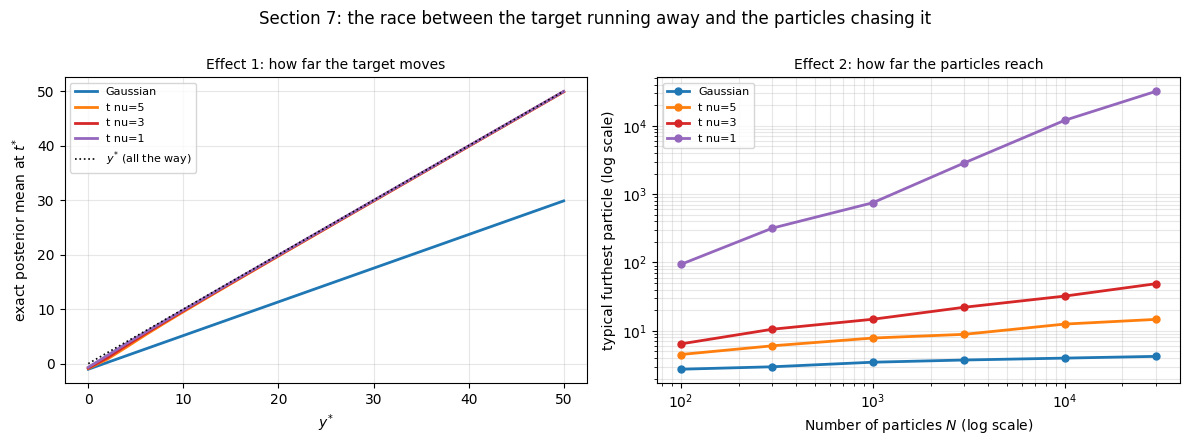

Typical furthest of N=1000 particles, and where the target sits at y*=20:

filter       furthest particle   target at y*=20     gap
Gaussian                   3.4              11.3     7.9
t nu=5                     7.4              19.7    12.3
t nu=3                    15.9              19.8     3.9
t nu=1                  1026.2              19.9 -1006.3

A positive gap means the target has escaped beyond the particles' reach.


In [14]:
ystars = np.linspace(0, 50, 26)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.4))

# Effect 1: where does each model's EXACT posterior mean go, as y* grows?
for name, noise, nu in OUT:
    means = []
    for ys in ystars:
        y = y_s.copy(); y[TSTAR] = ys
        ex, _, _ = grid_filter(y, b=B, a=A, Q=Q, R=R, noise=noise, nu=nu, h=0.05)
        means.append(ex[TSTAR])
    a1.plot(ystars, means, "-", color=COL[name], lw=2, label=name)
a1.plot(ystars, ystars, "k:", lw=1.2, label="$y^{*}$ (all the way)")
a1.set_xlabel("$y^{*}$"); a1.set_ylabel("exact posterior mean at $t^{*}$")
a1.set_title("Effect 1: how far the target moves", fontsize=10); a1.legend(fontsize=8)

# Effect 2: how far do N particles actually reach?
rng2 = np.random.default_rng(1)
Ns = np.array([100, 300, 1000, 3000, 10000, 30000])
for name, noise, nu in OUT:
    reach = []
    for n in Ns:
        draws = (rng2.standard_normal((60, n)) if nu is None
                 else rng2.standard_t(nu, size=(60, n)))
        reach.append(np.median(np.abs(draws).max(axis=1)))
    a2.loglog(Ns, reach, "o-", color=COL[name], lw=2, ms=5, label=name)
a2.set_xlabel("Number of particles $N$ (log scale)")
a2.set_ylabel("typical furthest particle (log scale)")
a2.set_title("Effect 2: how far the particles reach", fontsize=10)
a2.legend(fontsize=8); a2.grid(True, which="both", alpha=0.3)
fig.suptitle("Section 7: the race between the target running away and the particles chasing it", y=1.0)
plt.tight_layout(); plt.show()

print("Typical furthest of N=1000 particles, and where the target sits at y*=20:\n")
print(f"{'filter':10s}{'furthest particle':>20}{'target at y*=20':>18}{'gap':>8}")
for name, noise, nu in OUT:
    draws = (rng2.standard_normal((200, 1000)) if nu is None
             else rng2.standard_t(nu, size=(200, 1000)))
    reach = np.median(np.abs(draws).max(axis=1))
    y = y_s.copy(); y[TSTAR] = 20.0
    ex, _, _ = grid_filter(y, b=B, a=A, Q=Q, R=R, noise=noise, nu=nu, h=0.05)
    print(f"{name:10s}{reach:>20.1f}{ex[TSTAR]:>18.1f}{ex[TSTAR]-reach:>8.1f}")
print("\nA positive gap means the target has escaped beyond the particles' reach.")

**Conclusion.** The non-monotonicity is explained by the race. At $y^{*} = 20$ the Student-t models' exact
posteriors sit at about $19.7$–$19.9$, almost all the way out at the observation, while the
Gaussian's stops at $10.6$, barely half way. Meanwhile the furthest of $N = 1000$ particles reaches
only $3.4$ (Gaussian), $7.4$ ($\nu = 5$), $15.9$ ($\nu = 3$) — but about $1026$ for the Cauchy. So
the gap between target and reach is $+12.3$ at $\nu = 5$ (the target has escaped badly), $+7.2$ for
the Gaussian, $+3.9$ at $\nu = 3$, and $-1006$ at $\nu = 1$, where the particles overshoot the
target by three orders of magnitude and tracking is easy. The Gaussian sits in
between because both its target and its particles are short-ranged.

This also explains the $N$ dependence in Section 6: a Gaussian filter's reach grows like
$\sqrt{2\log N}$, so throwing particles at the problem barely helps, whereas the Cauchy's reach
grows like $N$.

---
## Section 8 — Larger $\nu$: locating the worst case

Section 5 compared four filters — Gaussian, $\nu = 5$, $3$, $1$ — and found the ordering
**non-monotonic**: $\nu = 5$ was the worst, $\nu = 1$ (Cauchy) the best, and the Gaussian in
between. Section 7 explained why, as a race between how far the filter's own target moves and how
far its particles can reach.

That leaves an obvious gap. Between $\nu = 5$ and the Gaussian ($\nu = \infty$) the curve must turn
around somewhere, since the Student-t *becomes* the Gaussian as $\nu \to \infty$. **Where?** The
four values tested so far cannot say.

This section sweeps $\nu$ from $1$ to $500$ at the stress-test setting, measuring the two quantities
Sections 5 and 6 used:

- the **RMSE of the log-likelihood estimate** (Section 6's metric, the sharper of the two: it
  penalises bias and variance together, and it was the one that survived the multi-dataset check);
- the **error of the filtering mean** at the outlier step (Section 5's metric).

Run at two outlier sizes, $y^{*} = 20$ and $y^{*} = 50$, so the location of the worst case can be
checked rather than assumed.

> **Added after feedback from Dr Gerber**, who noted that the rise in RMSE with $\nu$ is predicted
> by Section 5.3.2 of Del Moral & Gerber (2026) and suggested repeating the experiment at larger
> $\nu$. It also closes the open question recorded in this notebook's own Section 9.

y* = 20   (150 seeds, N=1000)
            nu  RMSE log p  err at t*   RMSE / Gaussian
             1        3.07       0.94              0.10
             2       41.82       3.95              1.42
             3       74.32       9.17              2.52
             5      101.56      13.78              3.45
             7      114.76      15.37              3.90   <- worst
            10      113.91      15.77              3.87
            15      107.84      16.04              3.66
            20       98.56      15.93              3.35
            30       83.28      15.65              2.83
            50       60.36      14.77              2.05
           100       39.67      12.61              1.35
           200       33.36      10.35              1.13
           500       30.75       9.21              1.04
      $\infty$       29.45       8.64              1.00
  worst case at nu = 7, 3.9x the Gaussian's RMSE

y* = 50   (150 seeds, N=1000)
            nu  RMSE log p  err at t*  

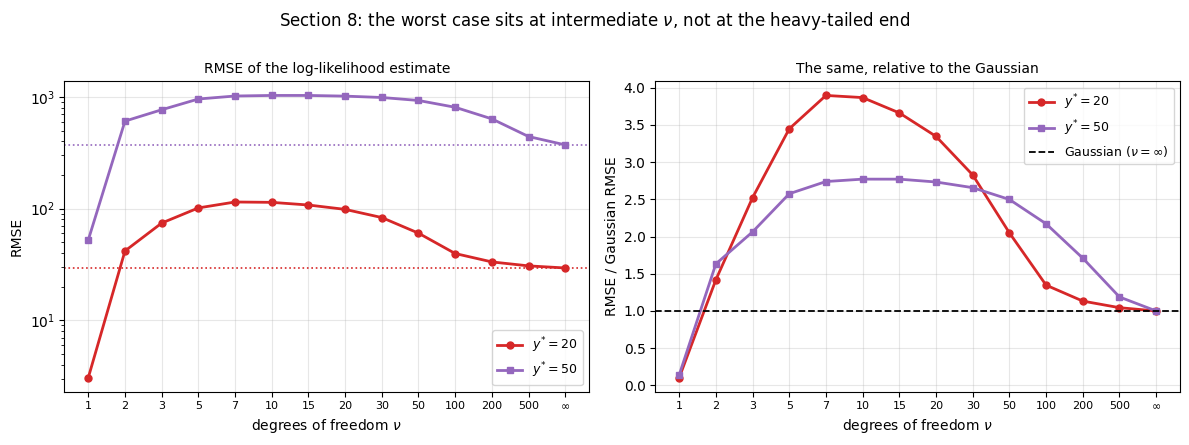

Dotted horizontal lines in the left panel mark each run's Gaussian value, i.e. nu = infinity.


In [15]:
NU_GRID = [1, 2, 3, 5, 7, 10, 15, 20, 30, 50, 100, 200, 500, None]   # None = Gaussian
NU_SEEDS = 150
YSTAR_SWEEP = (20.0, 50.0)

nu_res = {}
for ys in YSTAR_SWEEP:
    y = y_long[:T_V].copy()
    y[TSTAR] = ys
    rmse, errt = [], []
    for nu in NU_GRID:
        noise = "gaussian" if nu is None else "student_t"
        ex_m, _, ex_l = grid_filter(y, b=B, a=A, Q=Q, R=R, noise=noise, nu=nu, h=0.05)
        runs = [particle_filter_noise(y, N=N_PART, seed=k, b=B, a=A, Q=Q, R=R,
                                      noise=noise, nu=nu) for k in range(NU_SEEDS)]
        L = np.array([r[3][-1] for r in runs])
        E = np.array([r[0] for r in runs])
        rmse.append(np.sqrt(((L - ex_l[-1]) ** 2).mean()))
        errt.append(np.abs(E[:, TSTAR] - ex_m[TSTAR]).mean())
    nu_res[ys] = {"rmse": np.array(rmse), "errt": np.array(errt)}

labels = ["$\\infty$" if nu is None else str(nu) for nu in NU_GRID]
for ys in YSTAR_SWEEP:
    d = nu_res[ys]
    k = int(np.argmax(d["rmse"]))
    print(f"y* = {ys:.0f}   ({NU_SEEDS} seeds, N={N_PART})")
    print(f"  {'nu':>12}{'RMSE log p':>12}{'err at t*':>11}{'RMSE / Gaussian':>18}")
    for lab, r, e in zip(labels, d["rmse"], d["errt"]):
        mark = "   <- worst" if lab == labels[k] else ""
        print(f"  {lab:>12}{r:>12.2f}{e:>11.2f}{r/d['rmse'][-1]:>18.2f}{mark}")
    print(f"  worst case at nu = {labels[k]}, "
          f"{d['rmse'][k]/d['rmse'][-1]:.1f}x the Gaussian's RMSE\n")

# --- the shape of the curve ---
x = np.arange(len(NU_GRID))
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.4))
for ys, c, mk in zip(YSTAR_SWEEP, ("tab:red", "tab:purple"), ("o", "s")):
    d = nu_res[ys]
    a1.plot(x, d["rmse"], mk + "-", color=c, lw=2, ms=5, label=f"$y^{{*}} = {ys:.0f}$")
    a1.axhline(d["rmse"][-1], color=c, ls=":", lw=1.2)
    a2.plot(x, d["rmse"] / d["rmse"][-1], mk + "-", color=c, lw=2, ms=5,
            label=f"$y^{{*}} = {ys:.0f}$")
a2.axhline(1.0, color="black", ls="--", lw=1.3, label="Gaussian ($\\nu = \\infty$)")
for ax, ttl, yl in ((a1, "RMSE of the log-likelihood estimate", "RMSE"),
                    (a2, "The same, relative to the Gaussian", "RMSE / Gaussian RMSE")):
    ax.set_xticks(x); ax.set_xticklabels(labels, fontsize=8)
    ax.set_xlabel("degrees of freedom $\\nu$")
    ax.set_ylabel(yl); ax.set_title(ttl, fontsize=10); ax.legend(fontsize=9)
a1.set_yscale("log")
fig.suptitle("Section 8: the worst case sits at intermediate $\\nu$, not at the heavy-tailed end",
             y=1.0)
plt.tight_layout(); plt.show()

print("Dotted horizontal lines in the left panel mark each run's Gaussian value, i.e. nu = infinity.")

**Conclusion.** The curve again has an interior maximum, in roughly the same place.

| | $b = 0.9$ | $b = 1$ |
|---|---|---|
| worst $\nu$ at $y^{*} = 20$ | $10$ | $7$ |
| RMSE there, relative to the Gaussian | $3.2\times$ | $\mathbf{3.9\times}$ |
| worst $\nu$ at $y^{*} = 50$ | $10$ | $10$ |
| RMSE there, relative to the Gaussian | $2.6\times$ | $2.8\times$ |
| Gaussian RMSE at $y^{*} = 20$ | $40.07$ | $29.45$ |

> **Compared with Part 4 ($b = 0.9$).** The location of the worst case is stable — $\nu$ between $7$
> and $10$ at both spectral radii and both outlier sizes. What moves is the **size** of the penalty
> relative to the Gaussian, which is slightly larger here ($3.9\times$ against $3.2\times$) because
> the Gaussian's own RMSE falls while the Student-t's falls less. The qualitative picture is
> unchanged: both ends of the $\nu$ range are benign and the damage is done in a narrow interior
> band.

---
## Section 9 — Verdict at the threshold

### What the random-walk variant settles

Part 4 could not satisfy the conjecture's condition — *"if the observations are unbounded"* — because
at $b = 0.9$ in-model observations never exceeded about $4\sigma$. It recorded the obvious next test:
run at $b = 1$, where a random-walk state should produce much larger observations, and see whether
the filters separate without an artificial outlier.

**They do not.** The observations do become large — $|y|$ reaches $319$ over $10^5$ steps against
$11.67$ at $b = 0.9$, a factor of $27$ — and Section 3 still finds **no difference at all** between
Gaussian and Student-t filters on that data.

**So the level of the observation is not the dial. The innovation is.** A random walk carries the
filter along with it, so however far the state travels, each new observation is about as surprising
as the last: the "in sd units" column sits at $3.6$–$4.2$ at both spectral radii. Unbounded
observations in the ordinary sense are not sufficient; what is needed is an unbounded *surprise*,
and in-model data will not supply one at any spectral radius $\le 1$.

This is a negative result, and a useful one: it means Section 5's single-outlier probe is not just a
convenience but appears to be **necessary** to reach the regime the conjecture is about.

### What is unchanged

| | $b = 0.9$ | $b = 1$ |
|---|---|---|
| approximation error on in-model data | $\approx 0.028$, all filters | $0.028$–$0.031$, all filters |
| error at $y^{*} = 20$, Gaussian | $8.86$ | $8.63$ |
| error at $y^{*} = 20$, $\nu = 5$ | $15.07$ | $13.98$ |
| $\operatorname{Var}(\log \hat p)$ vs Gaussian, $\nu = 5$ | $10.3\times$ | $9.7\times$ |
| worst case over $\nu$ | $\nu = 10$ | $\nu = 7$–$10$ |

The conjecture's verdict is therefore the same as in Part 4: **partly supported**, holding for
moderate $\nu$ once a large innovation is supplied, failing as a monotone statement because the
Cauchy filter is the most stable of all, and invisible on in-model data.

### What changes

**Everything is noisier.** The 12-dataset confidence intervals are roughly three times wider than at
$b = 0.9$. With a random-walk state each dataset explores a different region, so the same experiment
has substantially more spread — worth knowing before designing any longer run at this spectral
radius.

**The relative penalty at the worst $\nu$ is a little larger** ($3.9\times$ against $3.2\times$),
because the Gaussian's own RMSE improves more than the Student-t's.

### Questions for the meeting

1. **Is "unbounded observations" the right condition, given this?** At $b \le 1$ the innovation
   stays $O(1)$ however large the observations get. Would an explosive state ($\rho(F) > 1$) produce
   genuinely unbounded innovations, or does the filter track that too? Part 5 suggests the posterior
   stays bounded when the state is observed, which would imply the innovation does as well.
2. **Does the worst case at $\nu \approx 10$ have an analytic location?** It is stable across two
   spectral radii and two outlier sizes, which suggests it is a property of the filter rather than
   of the particular stress.
3. **The scale/shape control is still incomplete** — a Gaussian filter run at the Student-t's
   reduced scale has not been run at either spectral radius.